In [1]:
import numpy as np
import matplotlib.pyplot as plt

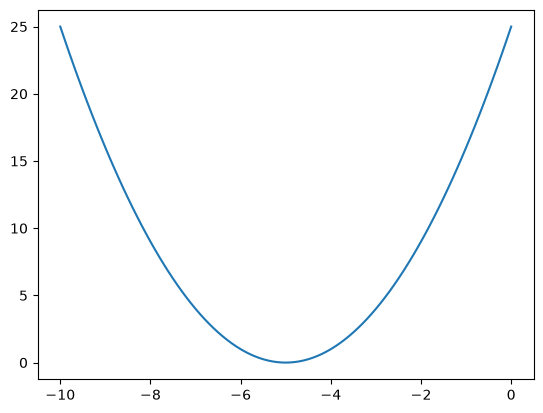

In [2]:
# Draw the graph --> estimate the minimum is -5
x = np.arange(-10, 0.001, 0.1)
y = (x + 5)**2
plt.plot(x, y)

In [3]:
# Parameters of algorithm
max_iters = 1000    # run n steps
precision = 0.0001  # fi - fi1 < epsilon 

# Given x, lr
lr        = 0.1     # learning rate
x         = 3       

for i in range(max_iters):
    print("Step %d: x = %f  --> f(x) = %f"%(i, x, (x+5)**2))
    dxy = 2 * (x + 5)
    f_pre = (x + 5) ** 2
    x = x - lr * (dxy)
    f_cur = (x + 5) ** 2
    if abs(f_cur - f_pre) < precision: 
        break
# for
print("The local minimum occurs at x=%f with f(x) = %f."%(x, (x + 5)**2))

Step 0: x = 3.000000  --> f(x) = 64.000000
Step 1: x = 1.400000  --> f(x) = 40.960000
Step 2: x = 0.120000  --> f(x) = 26.214400
Step 3: x = -0.904000  --> f(x) = 16.777216
Step 4: x = -1.723200  --> f(x) = 10.737418
Step 5: x = -2.378560  --> f(x) = 6.871948
Step 6: x = -2.902848  --> f(x) = 4.398047
Step 7: x = -3.322278  --> f(x) = 2.814750
Step 8: x = -3.657823  --> f(x) = 1.801440
Step 9: x = -3.926258  --> f(x) = 1.152922
Step 10: x = -4.141007  --> f(x) = 0.737870
Step 11: x = -4.312805  --> f(x) = 0.472237
Step 12: x = -4.450244  --> f(x) = 0.302231
Step 13: x = -4.560195  --> f(x) = 0.193428
Step 14: x = -4.648156  --> f(x) = 0.123794
Step 15: x = -4.718525  --> f(x) = 0.079228
Step 16: x = -4.774820  --> f(x) = 0.050706
Step 17: x = -4.819856  --> f(x) = 0.032452
Step 18: x = -4.855885  --> f(x) = 0.020769
Step 19: x = -4.884708  --> f(x) = 0.013292
Step 20: x = -4.907766  --> f(x) = 0.008507
Step 21: x = -4.926213  --> f(x) = 0.005445
Step 22: x = -4.940970  --> f(x) = 0.003

In [4]:
def perceptron_forward(x, W, b):
    # calculating f
    f = np.matmul(W.T, x) + b
    # activation step function
    if f>=0:
        return 1
    else:
        return -1
# forward

In [5]:
# Parameters of algorithm
max_iters = 1000    # run n steps
# Training Data
X = [(np.array([0,0]), -1), (np.array([1,0]), 1), (np.array([0,1]), 1), (np.array([1,1]), 1)] # [(xi, ti), ...]
N = len(X)
# Given lr, W, b
W = np.array([0, -1])
b = 0.5
p = 0.4

for step in range(max_iters):
    print("---------------------------------")
    print("Step %d: "%step)
    print("---------------------------------")
    
    # calculating gradient on training data
    print("- W = %s"%W)
    print("- b = %s"%b)
    print("- Training Data")
    
    count_misclas = 0
    dw = np.array([0, 0])
    db = 0
    for i in range(N): # training dataset
        xi = X[i][0]
        ti = X[i][1]
        
        yi = perceptron_forward(xi, W, b)
        print("(xi, ti) = (%s, %d)\t --> \tperceptron(xi)\t=\t%d"%(xi, ti, yi), end = '')
        
        is_miss_class = ti != yi
        if is_miss_class == True: # mis-class (x belong to Y)
            print("\tmis-classification", end = ' ')
            dw = dw  + (-ti)  * xi
            db = db  + (-ti)
            count_misclas = count_misclas + 1
            
            print("- update dw = %s"%dw, end = ' ')
            print("- update db = %s"%db, end = ' ')
        print()
    # for
    W = W - p * dw
    b = b - p * db
    print("- update W = %s"%W)
    print("- update b = %s"%b)
    
    if count_misclas == 0:
        break
# for

print("Perceptron has parametes: W=%s, b=%s"%(W, b))
for i in range(N):    
    print("Point i: [%s, %s] --> Perceptron(Xi) = %s"%(X[i][0], X[i][1], perceptron_forward(X[i][0], W, b)))

---------------------------------
Step 0: 
---------------------------------
- W = [ 0 -1]
- b = 0.5
- Training Data
(xi, ti) = ([0 0], -1)	 --> 	perceptron(xi)	=	1	mis-classification - update dw = [0 0] - update db = 1 
(xi, ti) = ([1 0], 1)	 --> 	perceptron(xi)	=	1
(xi, ti) = ([0 1], 1)	 --> 	perceptron(xi)	=	-1	mis-classification - update dw = [ 0 -1] - update db = 0 
(xi, ti) = ([1 1], 1)	 --> 	perceptron(xi)	=	-1	mis-classification - update dw = [-1 -2] - update db = -1 
- update W = [ 0.4 -0.2]
- update b = 0.9
---------------------------------
Step 1: 
---------------------------------
- W = [ 0.4 -0.2]
- b = 0.9
- Training Data
(xi, ti) = ([0 0], -1)	 --> 	perceptron(xi)	=	1	mis-classification - update dw = [0 0] - update db = 1 
(xi, ti) = ([1 0], 1)	 --> 	perceptron(xi)	=	1
(xi, ti) = ([0 1], 1)	 --> 	perceptron(xi)	=	1
(xi, ti) = ([1 1], 1)	 --> 	perceptron(xi)	=	1
- update W = [ 0.4 -0.2]
- update b = 0.5
---------------------------------
Step 2: 
--------------------------